# Answer the questions from the Preamble and Introduction

### a. Derive the formula for ELBO and explain why this loss is used for VAE training. 

$$p_\theta(x) = \int_{Z^M} p_\theta(x|z) p_\theta(z) dz \to \max_{\theta \in \Theta}

по методу монте карло интеграл можно представить как матожидание

$$\log p_\theta(x) = \log p_\theta(x) \cdot \int q_\phi(z|x) \, dz = \int q_\phi(z|x) \log p_\theta(x) \, dz = \mathbb{E}_{q_\phi(z|x)}[\log p_\theta(x)] \approx \frac{1}{K} \sum_{k=1}^{K} \log p_\theta(x)

основная проблема в том что p(x|z) является композицией линейных нейронных слоев, число линейных областей растет экспоненциально, теоретически можно разить интеграл на все области и посчитать его но на практике это практически неосуществимо

да и сам p(x|z) с декодера выдает логиты через софтмакс, где изза знаменателя нет элементарной первообразной то есть интеграл банально неберущийся, в предыдущих же проектах по сути задачи софтмакс нужно было дифференцировать а не интегрировать изза чего проблем не было в том же backprop

$$\log p_\theta(x) = \mathbb{E}_{q_\phi(z|x)}[\log p_\theta(x)] = \mathbb{E}_{q_\phi(z|x)}\left[\log\left(\frac{p_\theta(x,z)}{p_\theta(z|x)}\right)\right] = \mathbb{E}_{q_\phi(z|x)}\left[\log\left(\frac{p_\theta(x,z)}{q_\phi(z|x)} \cdot \frac{q_\phi(z|x)}{p_\theta(z|x)}\right)\right]

как я понял суть такой замены на латентное пространство в том что мы добавляем на помощь к неинтегрируемой функции после выхода декодера - энкодер с известным нам интегрируемым гаусовским распределением, энкодер через лосс функцию приближается к нашему исходного апостериорному распределению p(x|z). то есть те же самые z мы теперь уже сэмплируем из энкодера. софтмакс теперь остается но вычисляется лишь в конкретных точках латентного пространства без интеграла

$$ = \underbrace{\mathbb{E}_{q_\phi(z|x)}\left[\log\left(\frac{p_\theta(x,z)}{q_\phi(z|x)}\right)\right]}_{\mathcal{L}_{\theta,\phi}(x) \text{ (ELBO)}} + \underbrace{\mathbb{E}_{q_\phi(z|x)}\left[\log\left(\frac{q_\phi(z|x)}{p_\theta(z|x)}\right)\right]}_{D_{KL}(q_\phi(z|x) \| p_\theta(z|x))}

первый член - evidence lower bound, нижняя граница, тк KL дивергенция неотрицательна, как итог помогает оценивать качество восстановления декодером объекта x из латентного представления z.

второй - KL дивергенция, подталкивает энкодер быть ближе к априорному распределению

$$\mathcal{L}_{\theta,\phi}(x) = \mathbb{E}_{q_\phi(z|x)}\left[\log p_\theta(x,z) - \log q_\phi(z|x)\right] = \underbrace{\mathbb{E}_{q_\phi(z|x)}[\log p_\theta(x|z)]}_{\text{reconstruction loss}} - \underbrace{D_{KL}(q_\phi(z|x) \| p_\theta(z))}_{\text{regularization term}}

### b. Explain which loss is used for the generator and discriminator in GAN.

лосс функция для дискриминатора - бинарная кросс энтропия. D выдает 1 когда верно и 0 когда нет, дальше за счет логарифма лосс либо остается 0 либо улетает в бесконечность

$$\min_{\phi} \; \mathbb{E}_{x \sim p(x)}\big[-\log D_\phi(x)\big] + \mathbb{E}_{\hat{x} \sim q(x)}\big[-\log\big(1 - D_\phi(\hat{x})\big)\big]

лосс функция для генератора соответсвенно минимизирует вероятность угадывания дискриминатором

$$\mathcal{L}_G = \mathbb{E}_{\hat{x} \sim q(x)}\big[-\log D_\phi(\hat{x})\big]

# Generative Model of the Variational AutoEncoder

In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision.utils import make_grid
from torchvision import datasets, transforms
import seaborn
import matplotlib.pyplot as plt
import pickle
from tqdm import tqdm
import shutil
import os

In [2]:
transform = transforms.ToTensor()

mnist_path = '../datasets/MNIST'
if os.path.exists(mnist_path):
    shutil.rmtree(mnist_path, ignore_errors=True)
os.makedirs(f'{mnist_path}/raw', exist_ok=True)

train_dataset = datasets.MNIST(root='../datasets', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='../datasets', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

100%|██████████| 9.91M/9.91M [00:03<00:00, 3.22MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 228kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 1.78MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.70MB/s]


$$z = g(\varepsilon, x) = \mu + \varepsilon \cdot \sigma \sim N(\mu, \sigma^2)

In [ ]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU()
        )
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.rand_like(std)
        return mu + std * eps

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar   

$$\mathcal{L}_{\theta,\phi}(x) = \mathbb{E}_{q_\phi(z|x)}\left[\log p_\theta(x,z) - \log q_\phi(z|x)\right] = \underbrace{\mathbb{E}_{q_\phi(z|x)}[\log p_\theta(x|z)]}_{\text{reconstruction loss}} - \underbrace{D_{KL}(q_\phi(z|x) \| p_\theta(z))}_{\text{regularization term}}

$$D_{\text{KL}}\big(\mathcal{N}(\mu, \sigma^2) \parallel \mathcal{N}(0, 1)\big) = -\frac{1}{2} \big(1 + \log \sigma^2 - \mu^2 - \sigma^2 \big)


In [7]:
def elbo_loss(recon_x, x, mu, logvar):
    recon = F.binary_cross_entropy(recon_x, x, reduction='sum')
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon + kl

### a. Train VAE using the MNIST data set. Use a 2-dimensional vector as the latent vector. Use ELBO as loss function.

In [27]:
def train_vae(model, train_loader, epochs=50, lr=3e-4):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        for x, _ in train_loader:
            recon, mu, logvar = model(x)

            loss = elbo_loss(recon, x, mu, logvar)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader.dataset) 
        losses.append(avg_loss)

        print(f"epoch {epoch+1}/{epochs}, loss: {avg_loss}")

    return losses

In [28]:
vae = VAE()

vae_losses = train_vae(vae, train_loader)

epoch 1/50, loss: 214.1214090169271
epoch 2/50, loss: 167.75000875651043
epoch 3/50, loss: 162.95211155598957
epoch 4/50, loss: 160.06079365234376
epoch 5/50, loss: 157.40971943359375
epoch 6/50, loss: 155.26745032552083
epoch 7/50, loss: 153.68945411783855
epoch 8/50, loss: 152.46990483398437
epoch 9/50, loss: 151.43275545247397
epoch 10/50, loss: 150.58197080078125
epoch 11/50, loss: 149.73829921875
epoch 12/50, loss: 148.9592000813802
epoch 13/50, loss: 148.27983767903646
epoch 14/50, loss: 147.6672453450521
epoch 15/50, loss: 147.0284299641927
epoch 16/50, loss: 146.4307116048177
epoch 17/50, loss: 145.88220883789063
epoch 18/50, loss: 145.33872602539063
epoch 19/50, loss: 144.82420209960938
epoch 20/50, loss: 144.3794287109375
epoch 21/50, loss: 143.92487172851563
epoch 22/50, loss: 143.57013688151042
epoch 23/50, loss: 143.20673802083334
epoch 24/50, loss: 142.9073576497396
epoch 25/50, loss: 142.5355844889323
epoch 26/50, loss: 142.19445249023437
epoch 27/50, loss: 141.948808398

### b. Plot the distribution of the latent vectors using different colors for each digit.

In [29]:
vae.eval()
zs, labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        _, mu, _ = vae(x)
        zs.append(mu)
        labels.append(y)

z = torch.cat(zs).numpy()
labels = torch.cat(labels).numpy()

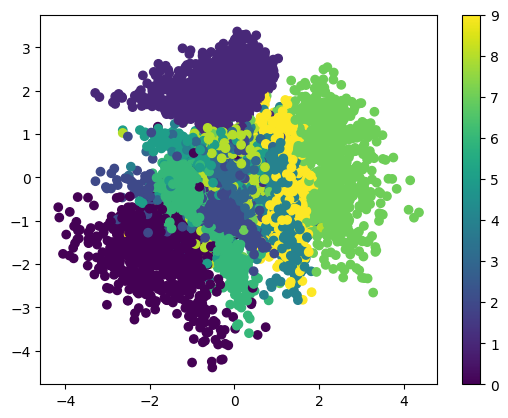

In [32]:
plt.figure()
plt.scatter(z[:, 0], z[:, 1], c=labels)
plt.colorbar()
plt.show()

### c. Create a 15x15 mesh in the 2-dimensional latent space. Use the decoder as a generator model to reconstruct handwritten digits. Combine all reconstructed digits into a 15x15 figure.

по правилу трех сигм для стандратного нормального распределния берем промежуток от -3 до 3, по формуле мю +- 3 сигма охватывает 99,7% выборки

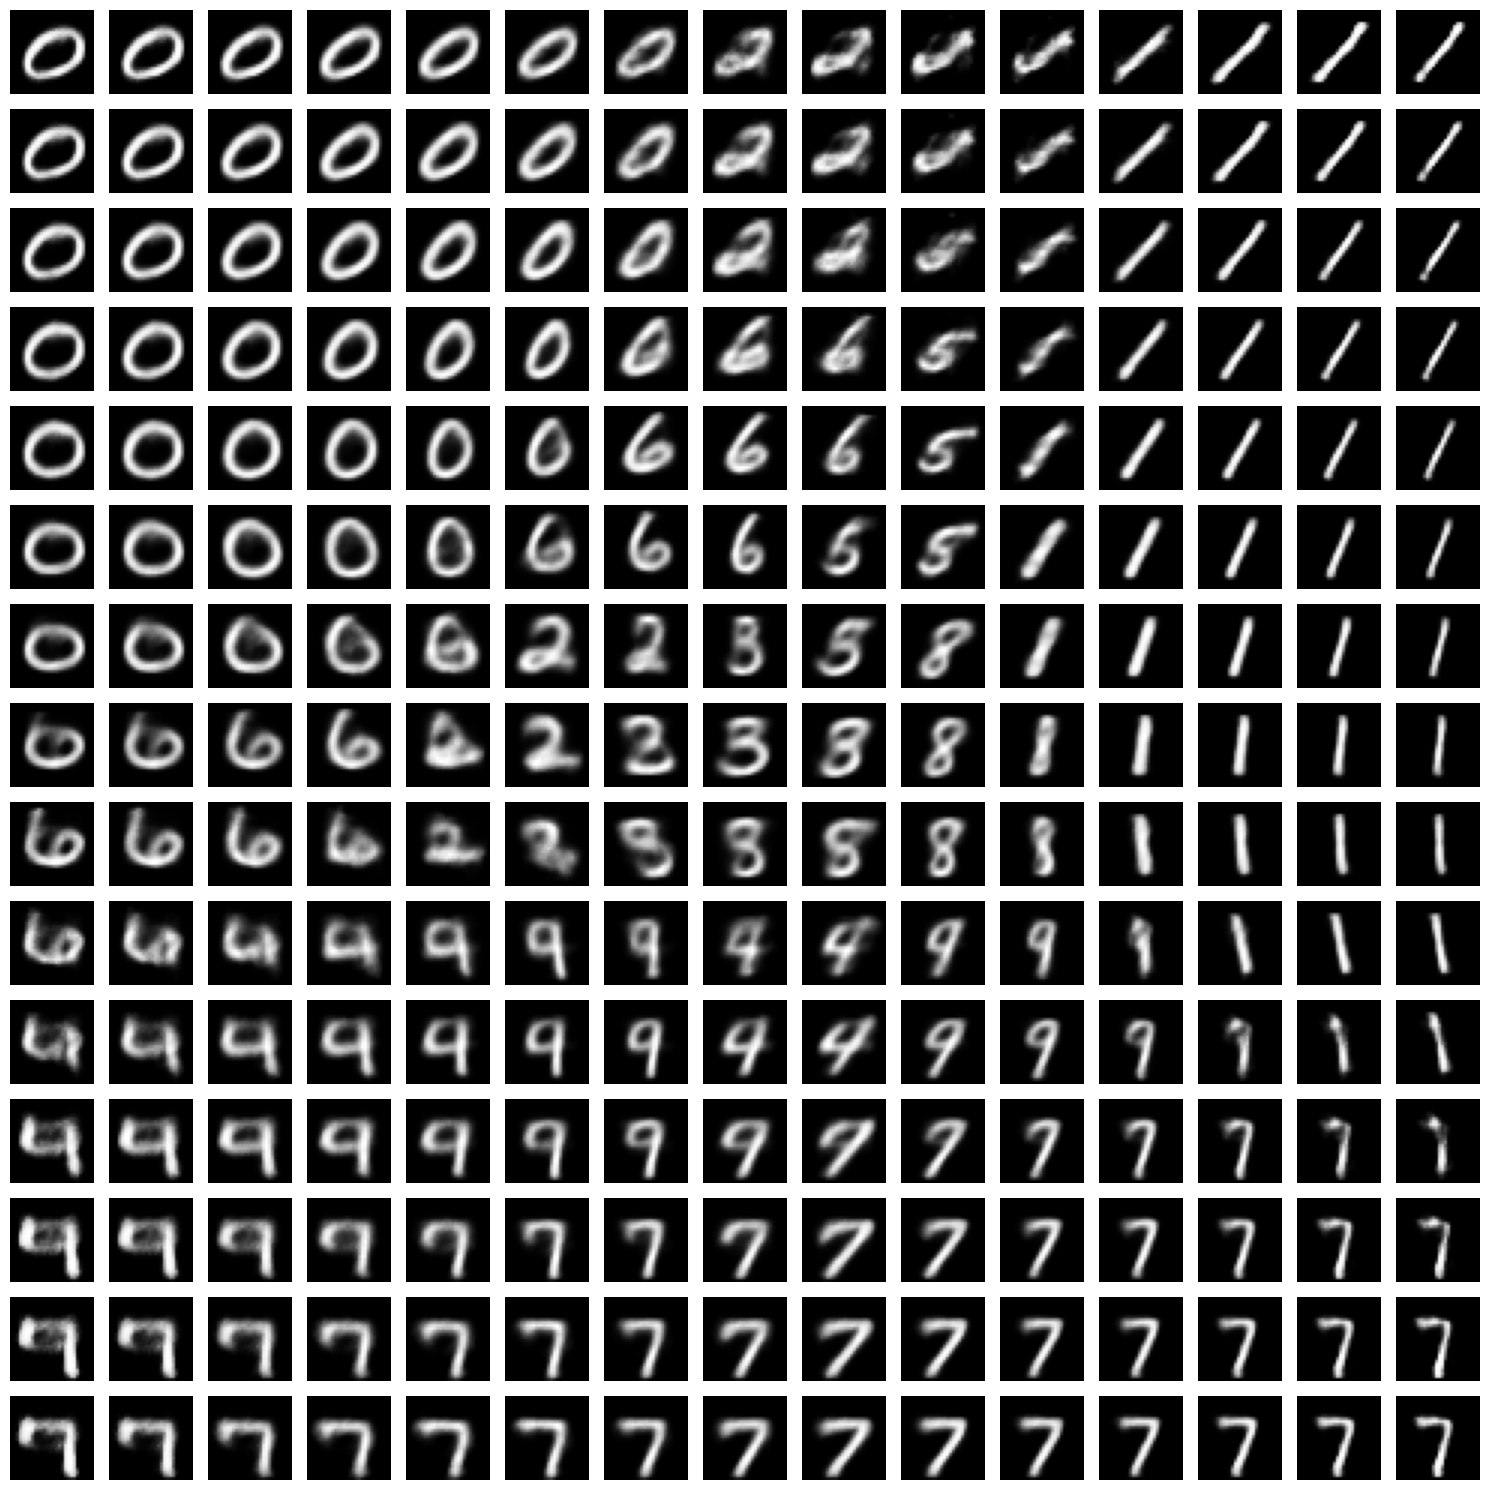

In [35]:
vae.eval()
grid = torch.linspace(-3, 3, 15)
fig, axes = plt.subplots(15, 15, figsize=(15, 15))

with torch.no_grad():
    for i, zi in enumerate(grid):
        for j, zj in enumerate(grid):
            z = torch.tensor([[zi, zj]], dtype=torch.float32)
            img = vae.decode(z).squeeze().numpy()
            axes[i, j].imshow(img, cmap='gray')
            axes[i, j].axis('off')

plt.tight_layout()
plt.show()

### d. What can you tell from the plots?

можно сказать что модель хорошо различает 1, 0, 9, 7. интересно наблюдать переходы от одной цифры к другой например от 7 к 9, или то что 6 между 0 и 9, как я понял это и есть интерполяция, то есть то, как модель распознает промежуточные значения, это можно обосновать общими паттернами которые смогла класифицировать наша модель, однако 2д пространтсва не хватает чтобы качественно все разделить

# Supervised Generative Model of VAE

### a. Train a supervised variational autoencoder using the MNIST dataset, where:

i. encoder returns 1-dimensional latent vector;

ii. decoder input consists of latent vector and digit label (as a single hot vector).

In [7]:
class SVAE(nn.Module):
    def __init__(self, latent_dim=1, num_classes=10):
        super().__init__()
        self.latent_dim = latent_dim
        self.num_classes = num_classes

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU()
        )
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim + num_classes, 128), nn.ReLU(),
            nn.Linear(128, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.rand_like(std)
        return mu + std * eps

    def decode(self, z, y):
        y_onehot = F.one_hot(y, num_classes=self.num_classes).float()
        zy = torch.cat([z, y_onehot], dim=-1)
        return self.decoder(zy).view(-1, 1, 28, 28)

    def forward(self, x, y):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z, y), mu, logvar   

In [8]:
def train_supervised_vae(model, train_loader, epochs=20, lr=3e-4):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        for x, y in train_loader:
            recon, mu, logvar = model(x, y)

            loss = elbo_loss(recon, x, mu, logvar)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader.dataset) 
        losses.append(avg_loss)

        print(f"epoch {epoch+1}/{epochs}, loss: {avg_loss}")

    return losses

In [12]:
svae = SVAE()

svae_losses = train_supervised_vae(svae, train_loader)

epoch 1/20, loss: 220.0074037434896
epoch 2/20, loss: 165.25362708333333
epoch 3/20, loss: 159.086712109375
epoch 4/20, loss: 156.13549334309897
epoch 5/20, loss: 154.05166459960938
epoch 6/20, loss: 152.09282770182293
epoch 7/20, loss: 150.49802892252603
epoch 8/20, loss: 149.30924134114582
epoch 9/20, loss: 148.41638500976563
epoch 10/20, loss: 147.59939767252604
epoch 11/20, loss: 146.9873701171875
epoch 12/20, loss: 146.48326529947917
epoch 13/20, loss: 145.91734983723958
epoch 14/20, loss: 145.50822679036457
epoch 15/20, loss: 145.12242534179688
epoch 16/20, loss: 144.7291990234375
epoch 17/20, loss: 144.4698625
epoch 18/20, loss: 144.14591373697917
epoch 19/20, loss: 143.83095890299478
epoch 20/20, loss: 143.60477259114583


### b. Create a mesh of 15 points in latent space. Combine them with 10 digit labels and plot 15x10 reconstructed digits. What can you tell from the plots?

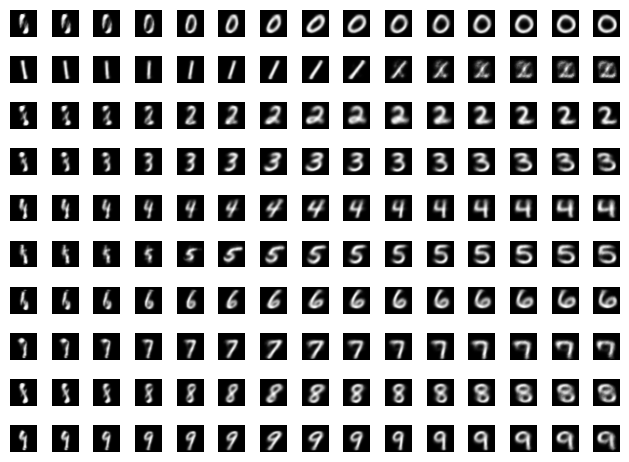

In [16]:
svae.eval()
z_grid = torch.linspace(-3, 3, 15)
labels = torch.arange(10)

fig, axis = plt.subplots(10, 15)
with torch.no_grad():
    for j, label in enumerate(labels):
        for i, zi in enumerate(z_grid):
            z = torch.tensor([[zi]], dtype=torch.float32)
            y = torch.tensor([label], dtype=torch.long)
            img = svae.decode(z, y).squeeze().numpy()
            axis[j, i].imshow(img, cmap='gray')
            axis[j, i].axis("off")

plt.tight_layout()
plt.show()

с точки зрения логики теперь латентное пространство не будет тратиться на запоминание лейблов, и в целом z будет описывать только вариации внутри классов. по графику тяжело что то сказать новое, видно лишь что возникают проблемы в начале столблоц и в конце у единички. ну а из плюсов, теперь в общих чертах все довольно четка и передавать метку класса декодеру действительно полезно

# Generative Adversarial Network

In [4]:
class Generator(nn.Module):
    def __init__(self, latent_dim=2, hidden=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden*2), nn.ReLU(),
            nn.Linear(hidden*2, 784), nn.Sigmoid()
        )

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

In [5]:
class Discriminator(nn.Module):
    def __init__(self, hidden=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, hidden*2), nn.LeakyReLU(0.2),
            nn.Linear(hidden*2, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, 1), nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)

In [8]:
class Generator(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(latent_dim, 128 * 7 * 7),
            nn.BatchNorm1d(128 * 7 * 7),
            nn.ReLU()
        )
        self.net = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 1, 4, 2, 1),
            nn.Sigmoid()
        )

    def forward(self, z):
        x = self.fc(z).view(-1, 128, 7, 7)
        return self.net(x)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 4, 2, 1),
            nn.LeakyReLU(0.2),
            nn.Conv2d(32, 64, 4, 2, 1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.LeakyReLU(0.2),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)

In [7]:
def train_gan(G, D, train_loader, epochs=30, lr_g=2e-4, lr_d=5e-5):
    opt_g = torch.optim.Adam(G.parameters(), lr=lr_g, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(D.parameters(), lr=lr_d, betas=(0.5, 0.999))

    criterion = nn.BCELoss()
    g_losses, d_losses = [], []
    for epoch in range(epochs):
        G.train()
        D.train()
        total_loss_g, total_loss_d = 0.0, 0.0
        for x, _ in train_loader:
            B = x.size(0)
            real = torch.ones(B, 1)
            fake = torch.zeros(B, 1)

            # z = torch.randn(B, 2)
            # fake_img = G(z)

            d_loss = criterion(D(x), real) + criterion(D(G(torch.randn(B, 2)).detach()), fake)
            opt_d.zero_grad()
            d_loss.backward()
            opt_d.step()

            for _ in range(3):
                g_loss = criterion(D(G(torch.randn(B, 2))), real)
                opt_g.zero_grad()
                g_loss.backward()
                opt_g.step()

            total_loss_d += d_loss.item()
            total_loss_g += g_loss.item()   

        g_losses.append(total_loss_g / len(train_loader))
        d_losses.append(total_loss_d / len(train_loader))      

        print(f"epoch {epoch+1}/{epochs}, generator loss: {g_losses[-1]:.4f}, discriminator loss: {d_losses[-1]:.4f}")

    return g_losses, d_losses

In [8]:
g = Generator()
d = Discriminator()

g_losses, d_losses = train_gan(g, d, train_loader, epochs=20)

epoch 1/20, generator loss: 0.7140, discriminator loss: 1.3760
epoch 2/20, generator loss: 0.7345, discriminator loss: 1.3530
epoch 3/20, generator loss: 0.7691, discriminator loss: 1.3120
epoch 4/20, generator loss: 0.8082, discriminator loss: 1.2738
epoch 5/20, generator loss: 0.8277, discriminator loss: 1.2527
epoch 6/20, generator loss: 0.8564, discriminator loss: 1.2233
epoch 7/20, generator loss: 0.8835, discriminator loss: 1.1912
epoch 8/20, generator loss: 0.8750, discriminator loss: 1.2042
epoch 9/20, generator loss: 0.8916, discriminator loss: 1.1799
epoch 10/20, generator loss: 0.9584, discriminator loss: 1.1052
epoch 11/20, generator loss: 0.9811, discriminator loss: 1.0881
epoch 12/20, generator loss: 0.9189, discriminator loss: 1.1610
epoch 13/20, generator loss: 0.9485, discriminator loss: 1.1423
epoch 14/20, generator loss: 0.9941, discriminator loss: 1.0919
epoch 15/20, generator loss: 1.0193, discriminator loss: 1.0695
epoch 16/20, generator loss: 1.0787, discriminato

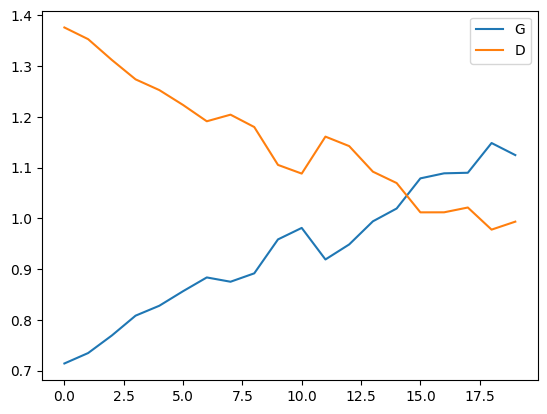

In [9]:
plt.figure()
plt.plot(g_losses, label='G')
plt.plot(d_losses, label='D')
plt.legend()
plt.show()

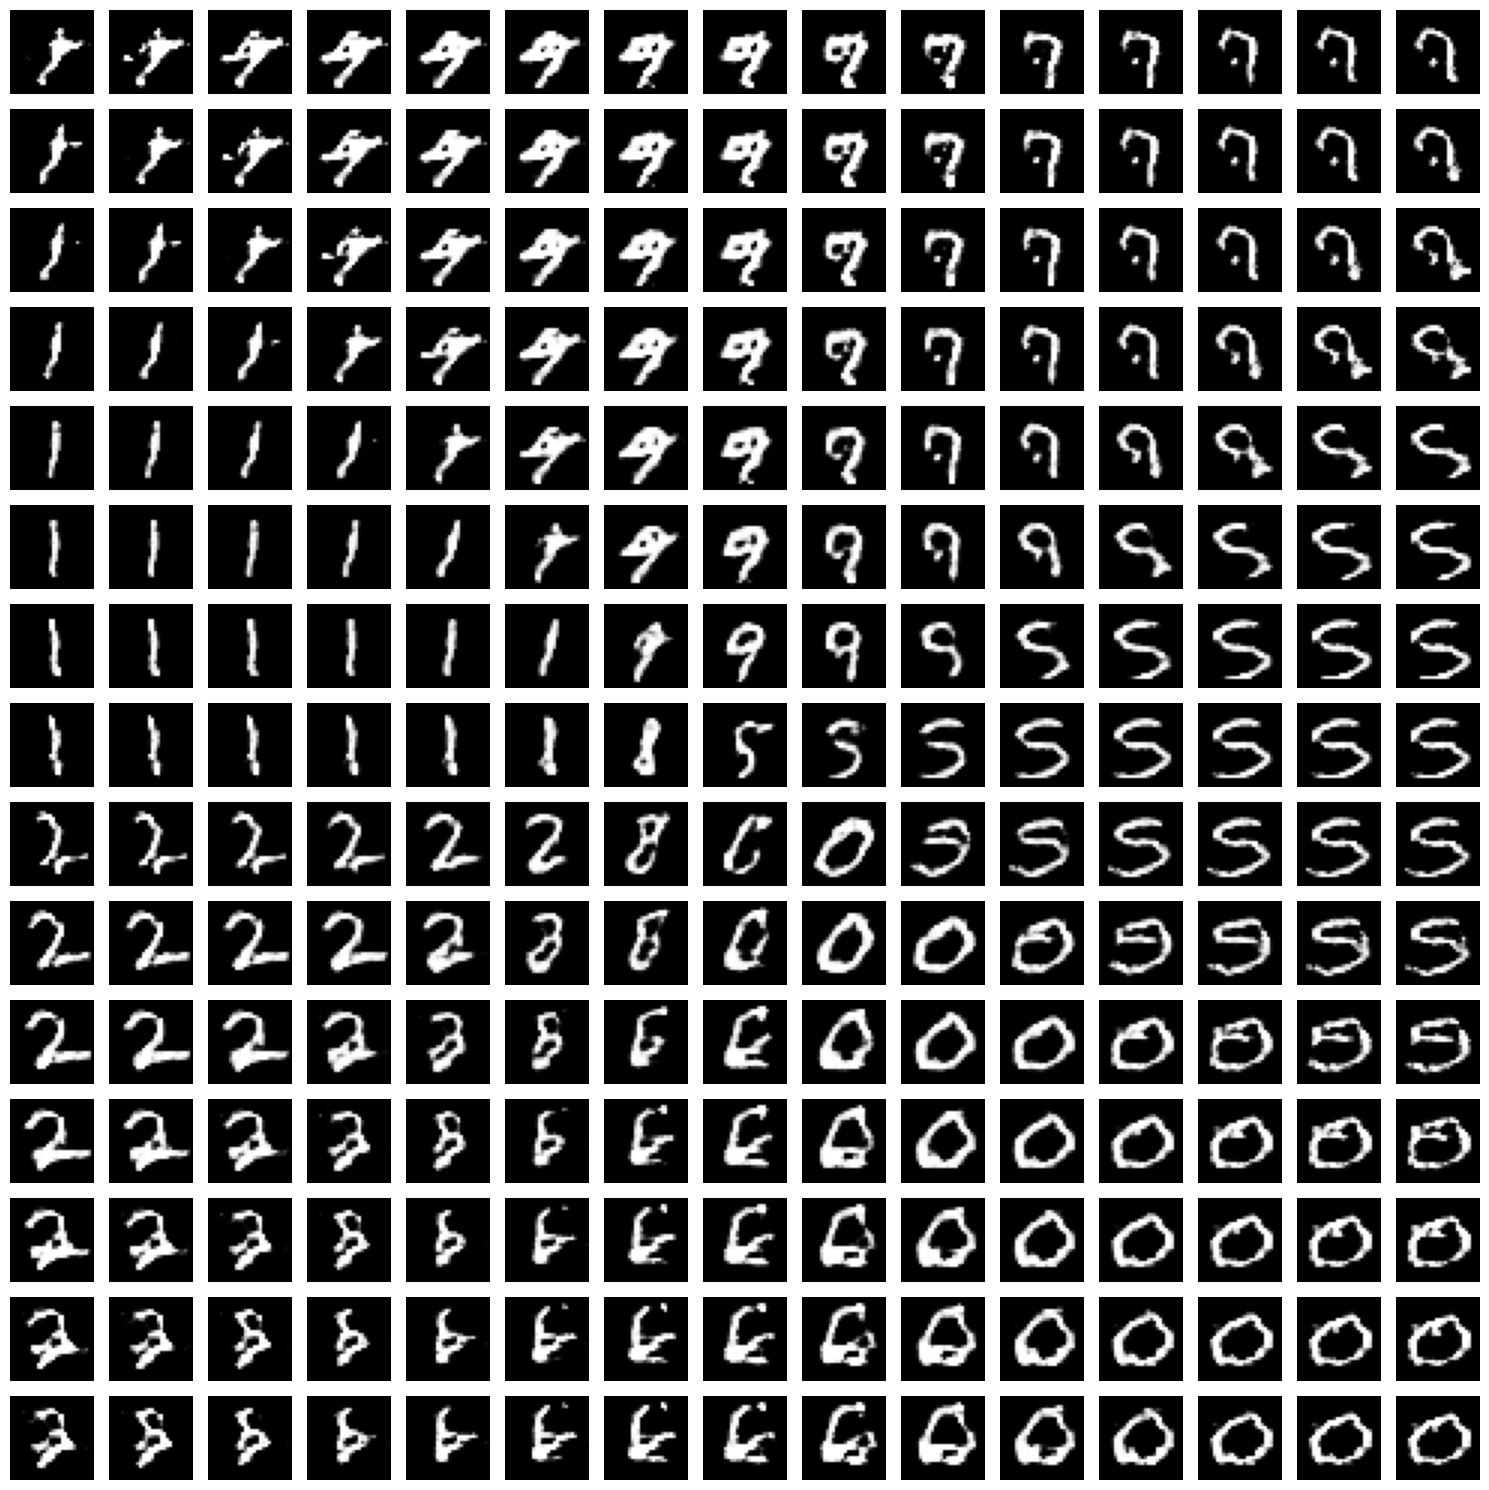

In [10]:
g.eval()
z_grid = torch.linspace(-3, 3, 15)
fig, axes = plt.subplots(15, 15, figsize=(15, 15))
with torch.no_grad():
    for i, zi in enumerate(z_grid):
        for j, zj in enumerate(z_grid):
            z = torch.tensor([[zi, zj]], dtype=torch.float32)
            axes[i, j].imshow(g(z).squeeze().numpy(), cmap='gray')
            axes[i, j].axis('off')
            
plt.tight_layout() 
plt.show()

# Gradient Reversal

In [9]:
class GradientReversalFn(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lambda_):
        ctx.lambda_ = lambda_
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        return -ctx.lambda_ * grad_output, None

In [10]:
class GradientReversalLayer(nn.Module):
    def __init__(self, lambda_=1.0):
        super().__init__()
        self.lambda_ = lambda_

    def forward(self, x):
        return GradientReversalFn.apply(x, self.lambda_)

In [11]:
def train_grl(G, D, train_loader, epochs=30, lr=3e-4, lambda_=1.0):
    opt = torch.optim.Adam([
        {'params': G.parameters(), 'lr': 2e-4},
        {'params': D.parameters(), 'lr': 5e-5}
    ], betas=(0.5, 0.999))

    criterion = nn.BCELoss()
    grl = GradientReversalLayer(lambda_=lambda_)
    losses = []
    d_losses, g_losses = [], []
    for epoch in range(epochs):
        G.train()
        D.train()
        total_loss = 0.0
        for x, _ in train_loader:
            B = x.size(0)
            real = torch.ones(B, 1) * 0.9
            fake = torch.zeros(B, 1)

            D_real = D(x)
            z = torch.randn(B, 2)
            img_fake = G(z)
            D_fake = D(grl(img_fake))


            loss = criterion(D_real, real) + criterion(D_fake, fake)
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(list(G.parameters())+list(D.parameters()), max_norm=1.0)
            
            with torch.no_grad():
                d_real = criterion(D(x), real).item()
                d_fake = criterion(D(img_fake), fake).item()
                g_adv  = criterion(D(img_fake), real).item()

            opt.step()

            total_loss += loss.item()


            d_losses.append(d_real+d_fake)
            g_losses.append(g_adv)

        losses.append(total_loss / len(train_loader))      

        D_mean = np.mean(d_losses[-len(train_loader):])
        G_mean = np.mean(g_losses[-len(train_loader):])

        print(f"epoch {epoch+1}/{epochs}, loss: {losses[-1]:.4f}, D: {D_mean:.4f}, G: {G_mean:.4f}")

    return d_losses, g_losses, losses

In [12]:
D = Discriminator()
G = Generator()

d_losses, g_losses, losses = train_grl(G, D, train_loader, epochs=20)

epoch 1/20, loss: 0.6070, D: 0.6070, G: 2.1744
epoch 2/20, loss: 0.6520, D: 0.6520, G: 1.9902
epoch 3/20, loss: 0.6972, D: 0.6972, G: 1.8684
epoch 4/20, loss: 0.6755, D: 0.6755, G: 1.8838
epoch 5/20, loss: 0.6783, D: 0.6783, G: 1.9152
epoch 6/20, loss: 0.6282, D: 0.6282, G: 2.2156
epoch 7/20, loss: 0.6007, D: 0.6007, G: 2.3364
epoch 8/20, loss: 0.5996, D: 0.5996, G: 2.4146
epoch 9/20, loss: 0.6144, D: 0.6144, G: 2.6348
epoch 10/20, loss: 0.6384, D: 0.6384, G: 2.7699
epoch 11/20, loss: 0.6741, D: 0.6741, G: 2.3793
epoch 12/20, loss: 0.6322, D: 0.6322, G: 2.3281
epoch 13/20, loss: 0.6841, D: 0.6841, G: 2.3804
epoch 14/20, loss: 0.7850, D: 0.7850, G: 2.1897
epoch 15/20, loss: 0.7149, D: 0.7149, G: 2.1603
epoch 16/20, loss: 0.7313, D: 0.7313, G: 2.1814
epoch 17/20, loss: 0.7686, D: 0.7686, G: 2.0071
epoch 18/20, loss: 0.7753, D: 0.7753, G: 1.8546
epoch 19/20, loss: 0.7656, D: 0.7656, G: 1.8705
epoch 20/20, loss: 0.7743, D: 0.7743, G: 1.9485


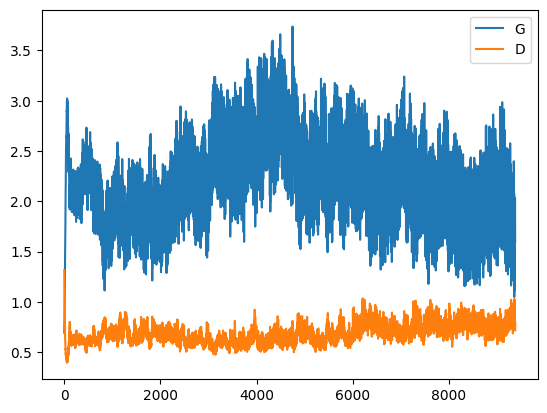

In [15]:
plt.figure()
plt.plot(g_losses, label='G')
plt.plot(d_losses, label='D')
plt.legend()
plt.show()

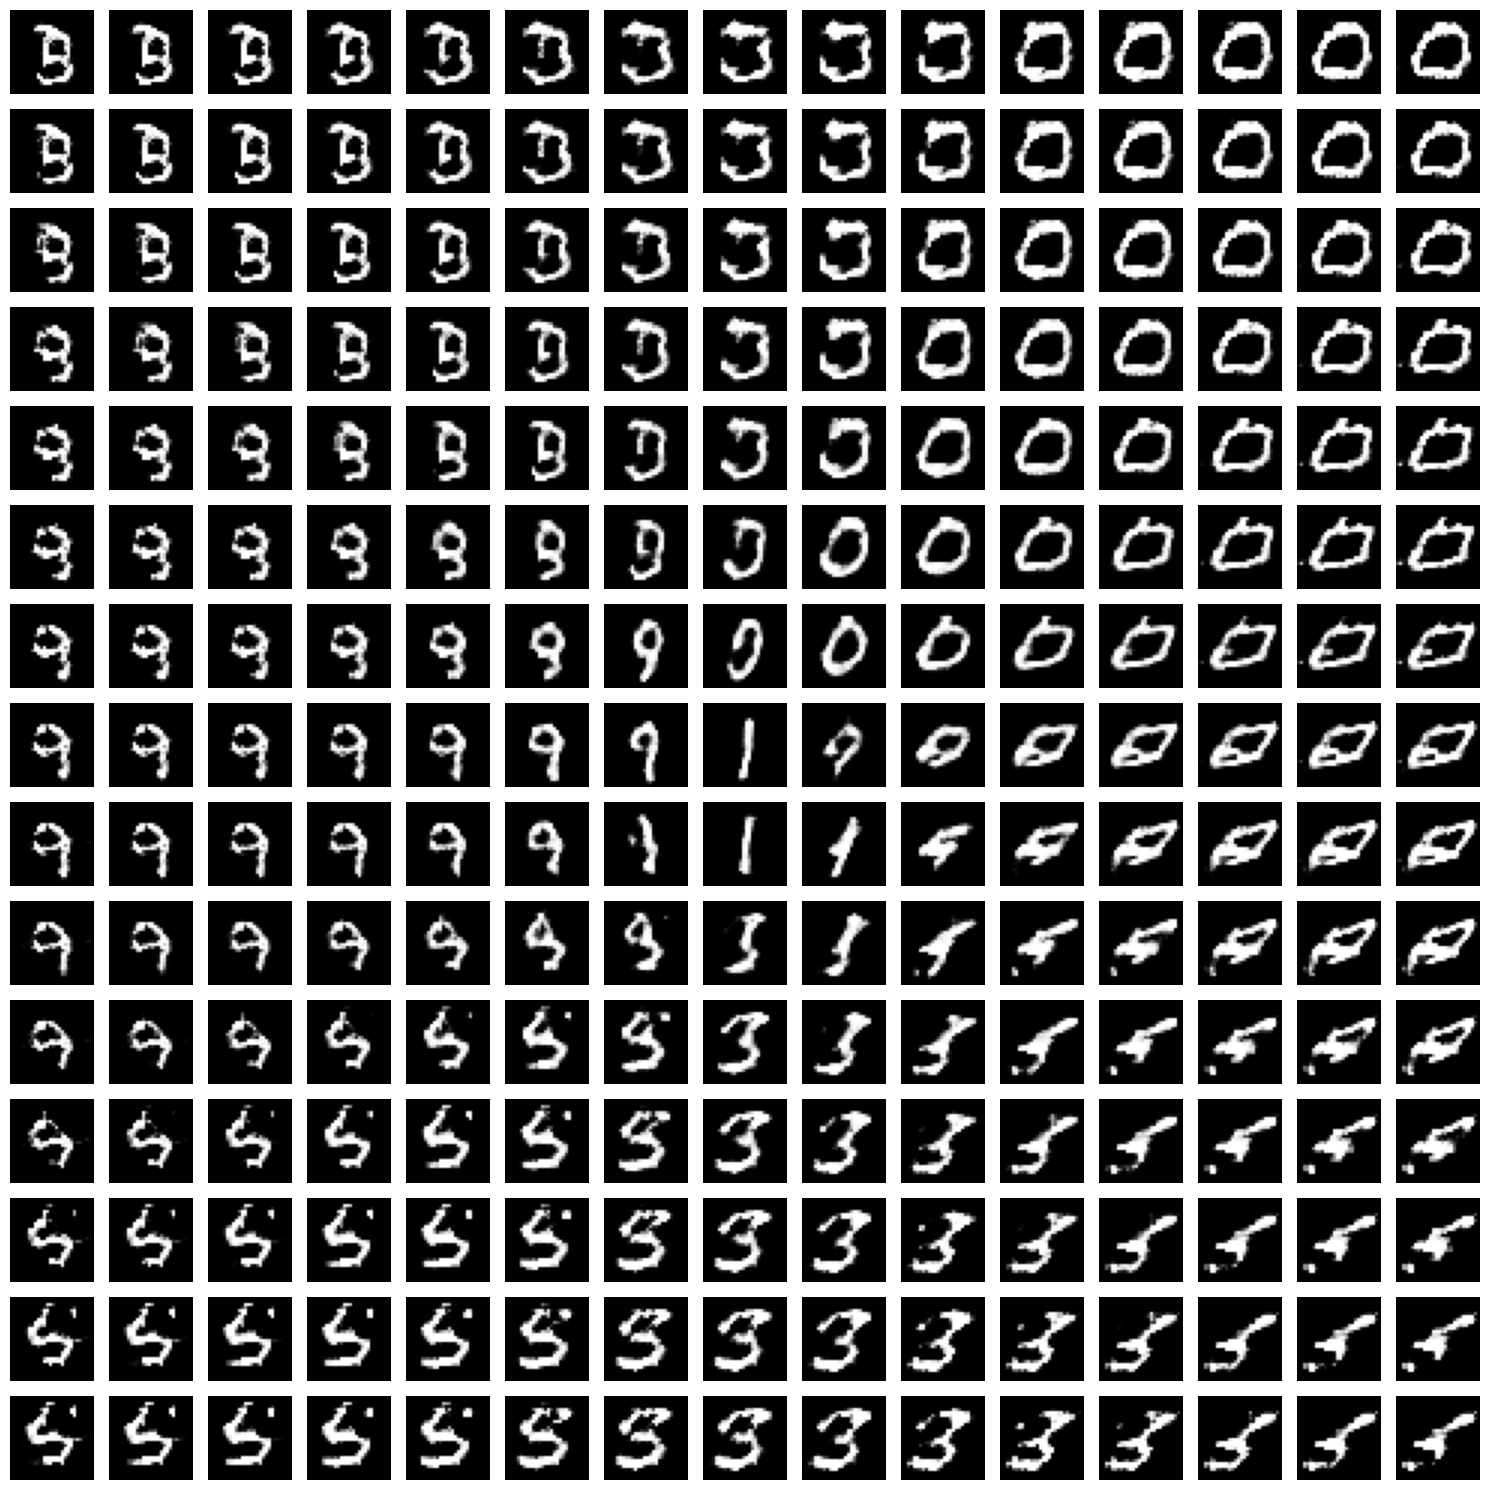

In [14]:
G.eval()
z_grid = torch.linspace(-3, 3, 15)
fig, axes = plt.subplots(15, 15, figsize=(15, 15))
with torch.no_grad():
    for i, zi in enumerate(z_grid):
        for j, zj in enumerate(z_grid):
            z = torch.tensor([[zi, zj]], dtype=torch.float32)
            axes[i, j].imshow(G(z).squeeze().numpy(), cmap='gray')
            axes[i, j].axis('off')
            
plt.tight_layout() 
plt.show()

# Supervised Generative Adversarial Network

In [43]:
class SGenerator(nn.Module):
    def __init__(self, latent_dim=2, num_classes=10, hidden=256):
        super().__init__()
        self.num_classes = num_classes
        self.net = nn.Sequential(
            nn.Linear(latent_dim+num_classes, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden*2), nn.ReLU(),
            nn.Linear(hidden*2, 784), nn.Sigmoid()
        )

    def forward(self, z, y):
        y_onehot = F.one_hot(y, num_classes=self.num_classes).float()
        zy = torch.cat([z, y_onehot], dim=-1)
        return self.net(zy).view(-1, 1, 28, 28)

    
class SDiscriminator(nn.Module):
    def __init__(self, num_classes=10, hidden=256):
        super().__init__()
        self.num_classes = num_classes
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784 + num_classes, hidden*2), nn.LeakyReLU(0.2),
            nn.Linear(hidden*2, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, 1), nn.Sigmoid()
        )

    def forward(self, x, y):
        x_flat = x.view(x.size(0), -1)
        y_onehot = F.one_hot(y, num_classes=self.num_classes).float()
        xy = torch.cat([x_flat, y_onehot], dim=-1)
        return self.net(xy)

In [17]:
class SGenerator(nn.Module):
    def __init__(self, latent_dim=2, num_classes=10):
        super().__init__()
        self.num_classes = num_classes

        self.fc = nn.Sequential(
            nn.Linear(latent_dim + num_classes, 128 * 7 * 7),
            nn.BatchNorm1d(128 * 7 * 7),
            nn.ReLU()
        )

        self.net = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 1, 4, 2, 1),
            nn.Sigmoid()
        )

    def forward(self, z, y):
        y_onehot = F.one_hot(y, num_classes=self.num_classes).float()
        zy = torch.cat([z, y_onehot], dim=1)
        x = self.fc(zy).view(-1, 128, 7, 7)
        return self.net(x)



class SDiscriminator(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.num_classes = num_classes

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 4, 2, 1),
            nn.LeakyReLU(0.2),
            nn.Conv2d(32, 64, 4, 2, 1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2)
        )

        self.classifier = nn.Sequential(
            nn.Linear(64 * 7 * 7 + num_classes, 128),
            nn.LeakyReLU(0.2),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

    def forward(self, x, y):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        y_onehot = F.one_hot(y, num_classes=self.num_classes).float()
        xy = torch.cat([x, y_onehot], dim=1)
        return self.classifier(xy)

In [19]:
def train_sgan(G, D, train_loader, epochs=30, lr_g=2e-4, lr_d=5e-5):
    opt_g = torch.optim.Adam(G.parameters(), lr=lr_g, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(D.parameters(), lr=lr_d, betas=(0.5, 0.999))

    criterion = nn.BCELoss()
    g_losses, d_losses = [], []
    for epoch in range(epochs):
        G.train()
        D.train()
        total_loss_g, total_loss_d = 0.0, 0.0
        for x, y in train_loader:
            B = x.size(0)
            real = torch.ones(B, 1)
            fake = torch.zeros(B, 1)

            d_loss = criterion(D(x, y), real) + criterion(D(G(torch.randn(B, 2), y).detach(), y), fake)
            opt_d.zero_grad()
            d_loss.backward()
            opt_d.step()

            for _ in range(3):
                g_loss = criterion(D(G(torch.randn(B, 2), y), y), real)
                opt_g.zero_grad()
                g_loss.backward()
                opt_g.step()

            total_loss_d += d_loss.item()
            total_loss_g += g_loss.item()   

        g_losses.append(total_loss_g / len(train_loader))
        d_losses.append(total_loss_d / len(train_loader))      

        print(f"epoch {epoch+1}/{epochs}, generator loss: {g_losses[-1]:.4f}, discriminator loss: {d_losses[-1]:.4f}")

    return g_losses, d_losses

In [20]:
sg = SGenerator()
sd = SDiscriminator()

g_losses, d_losses = train_sgan(sg, sd, train_loader, epochs=20)

epoch 1/20, generator loss: 0.7102, discriminator loss: 1.3652
epoch 2/20, generator loss: 0.7074, discriminator loss: 1.3698
epoch 3/20, generator loss: 0.7070, discriminator loss: 1.3662
epoch 4/20, generator loss: 0.7057, discriminator loss: 1.3702
epoch 5/20, generator loss: 0.7031, discriminator loss: 1.3778
epoch 6/20, generator loss: 0.7027, discriminator loss: 1.3782
epoch 7/20, generator loss: 0.7015, discriminator loss: 1.3788
epoch 8/20, generator loss: 0.7033, discriminator loss: 1.3769
epoch 9/20, generator loss: 0.7062, discriminator loss: 1.3710
epoch 10/20, generator loss: 0.7055, discriminator loss: 1.3740
epoch 11/20, generator loss: 0.7038, discriminator loss: 1.3770
epoch 12/20, generator loss: 0.7050, discriminator loss: 1.3737
epoch 13/20, generator loss: 0.7063, discriminator loss: 1.3720
epoch 14/20, generator loss: 0.7074, discriminator loss: 1.3697
epoch 15/20, generator loss: 0.7105, discriminator loss: 1.3662
epoch 16/20, generator loss: 0.7139, discriminato

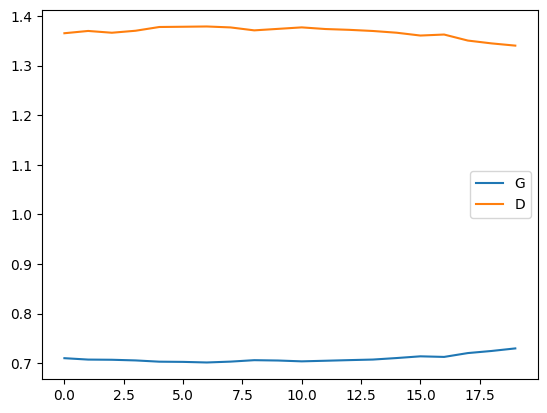

In [21]:
plt.figure()
plt.plot(g_losses, label='G')
plt.plot(d_losses, label='D')
plt.legend()
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_22792\1616483395.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


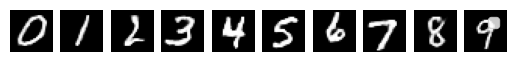

In [22]:
sg.eval()

z_fixed = torch.randn(1, 2)
labels = torch.arange(10)

fig, axes = plt.subplots(1, 10)

with torch.no_grad():
    for i, label in enumerate(labels):
        y = torch.tensor([label])
        img = sg(z_fixed, y).squeeze().numpy()
        axes[i].imshow(img, cmap='gray')
        axes[i].axis('off')


plt.legend()
plt.show()

In [23]:
sg = SGenerator()
sd = SDiscriminator()

g_losses, d_losses = train_sgan(sg, sd, train_loader, epochs=2)

epoch 1/2, generator loss: 0.7039, discriminator loss: 1.3731
epoch 2/2, generator loss: 0.7003, discriminator loss: 1.3783


C:\Users\user\AppData\Local\Temp\ipykernel_22792\1616483395.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


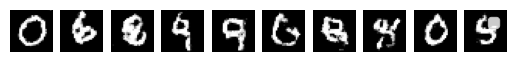

In [24]:
sg.eval()

z_fixed = torch.randn(1, 2)
labels = torch.arange(10)

fig, axes = plt.subplots(1, 10)

with torch.no_grad():
    for i, label in enumerate(labels):
        y = torch.tensor([label])
        img = sg(z_fixed, y).squeeze().numpy()
        axes[i].imshow(img, cmap='gray')
        axes[i].axis('off')


plt.legend()
plt.show()

# Bonus Part

In [8]:
class Denoiser(nn.Module):
    def __init__(self, time_dim=128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            nn.Linear(time_dim, 128), nn.SiLU(),
            nn.Linear(128, 64)
        )
        self.conv1 = nn.Conv2d(1, 64, 3, padding=1)
        self.conv2 = nn.Conv2d(64, 64, 3, padding=1)
        self.conv3 = nn.Conv2d(64, 1, 3, padding=1)

    def time_embedding(self, t, time_dim=128):
        half = time_dim // 2
        emb = torch.log(torch.tensor(10000.0)) / (half-1)
        emb = torch.exp(torch.arange(half)*-emb)
        emb = t.float().unsqueeze(1) * emb.unsqueeze(0)
        return torch.cat([torch.sin(emb), torch.cos(emb)], dim=1)

    def forward(self, x, t):
        t_emb = self.time_mlp(self.time_embedding(t))
        h = F.silu(self.conv1(x))
        h = self.conv2(h) + t_emb[:, :, None, None]
        h = F.silu(h)
        return self.conv3(h)

$$
\begin{aligned}
&\alpha_t = 1 - \beta_t\\[6pt]
&\bar\alpha_t = \prod_{s=0}^{t} \alpha_s\\[6pt]
&\text{Forward:} \quad x_t = \sqrt{\bar\alpha_t}\, x_0 + \sqrt{1-\bar\alpha_t}\, \epsilon \\[6pt]
&\text{Loss:} \quad \mathcal{L} = \left\| \epsilon - \epsilon_\theta(x_t, t) \right\|^2 \\[6pt]
&\text{Reverse mean:} \quad \mu_\theta(x_t, t) = \frac{1}{\sqrt{\alpha_t}} \left( x_t - \frac{1-\alpha_t}{\sqrt{1-\bar\alpha_t}}\, \epsilon_\theta(x_t, t) \right) \\[6pt]
&\text{Reverse variance:} \quad \tilde\beta_t = \beta_t \cdot \frac{1 - \bar\alpha_{t-1}}{1 - \bar\alpha_t} \\[6pt]
&\text{Sampling:} \quad x_{t-1} = \mu_\theta(x_t, t) + \sqrt{\tilde\beta_t}\, z, \quad z \sim \mathcal{N}(0, I)
\end{aligned}

In [34]:
T = 300

betas = torch.linspace(1e-4, 0.02, T)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

sqrt_alpha_bar = torch.sqrt(alpha_bars)
sqrt_minus_one_alpha_bar = torch.sqrt(1-alpha_bars)

alpha_bars_prev = F.pad(alpha_bars[:-1], (1, 0), value=1.0)

posterior_var = betas * (1-alpha_bars_prev) / (1-alpha_bars)

In [17]:
def forward_diffusion(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)

    sqrt_ab = sqrt_alpha_bar[t].view(-1, 1, 1, 1)
    sqrt_one_ab = sqrt_minus_one_alpha_bar[t].view(-1, 1, 1, 1)

    xt = sqrt_ab * x0 + sqrt_one_ab * noise

    return xt, noise

In [18]:
def train_diffusion(model, train_loader, epochs=20, lr=3e-4):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        for x, _ in train_loader:
            x = x * 2 - 1

            B = x.size(0)
            t = torch.randint(0, T, (B,))

            xt, noise = forward_diffusion(x, t)
            pred_noise = model(xt, t)

            loss = F.mse_loss(pred_noise, noise)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        losses.append(avg_loss)
        print(f"epoch {epoch+1}/{epochs}, diffusion loss: {avg_loss:.4f}")

    return losses    

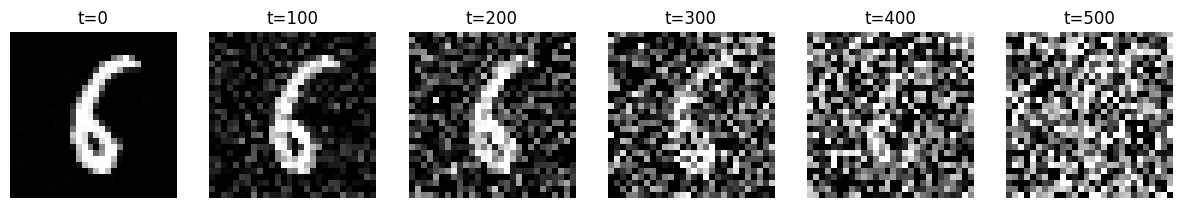

In [32]:
x, _ = next(iter(train_loader))
x = x[:1]
x = x * 2 - 1

timesteps = [0, 100, 200, 300, 400, 500]

fig, axes = plt.subplots(1, len(timesteps), figsize=(15, 3))

for i, t in enumerate(timesteps):
    tt = torch.tensor([t])
    xt, _ = forward_diffusion(x, tt)
    img = ((xt[0] + 1) / 2).clamp(0, 1)

    axes[i].imshow(
        img.squeeze(),
        cmap='gray',
        vmin=0,
        vmax=1
    )

    axes[i].set_title(f't={t}')
    axes[i].axis('off')

In [ ]:
class Denoiser(nn.Module):
    def __init__(self, time_dim=128):
        super().__init__()

        self.time_mlp = nn.Sequential(
            nn.Linear(time_dim, 128), nn.SiLU(),
            nn.Linear(128, 128)
        )

        self.in_conv = nn.Conv2d(1, 32, 3, padding=1)

        self.down1 = nn.Conv2d(32, 64, 4, 2, 1)
        self.down2 = nn.Conv2d(64, 128, 4, 2, 1)

        self.mid = nn.Sequential(
            nn.Conv2d(128, 128, 3, padding=1),
            nn.GroupNorm(8, 128),
            nn.SiLU(),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.GroupNorm(8, 128),
            nn.SiLU()
        )

        self.up1 = nn.ConvTranspose2d(128, 64, 4, 2, 1)
        self.up1_conv = nn.Sequential(
            nn.Conv2d(128, 64, 3, padding=1),
            nn.GroupNorm(8, 64),
            nn.SiLU()
        )

        self.up2 = nn.ConvTranspose2d(64, 32, 4, 2, 1)
        self.up2_conv = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1),
            nn.GroupNorm(8, 32),
            nn.SiLU()
        )

        self.out_conv = nn.Conv2d(32, 1, 3, padding=1)

        self.time_down1 = nn.Linear(128, 64)
        self.time_down2 = nn.Linear(128, 128)
        self.time_mid = nn.Linear(128, 128)

    def time_embedding(self, t, time_dim=128):
        half = time_dim // 2
        emb = torch.log(torch.tensor(10000.0)) / (half-1)
        emb = torch.exp(torch.arange(half)*-emb)
        emb = t.float().unsqueeze(1) * emb.unsqueeze(0)
        return torch.cat([torch.sin(emb), torch.cos(emb)], dim=1)

    def forward(self, x, t):
        t_emb = self.time_mlp(self.time_embedding(t))

        x1 = F.silu(self.in_conv(x))

        x2 = self.down1(x1)
        x2 = x2 + self.time_down1(t_emb)[:, :, None, None]
        x2 = F.silu(x2)

        x3 = self.down2(x2)
        x3 = x3 + self.time_down2(t_emb)[:, :, None, None]
        x3 = F.silu(x3)

        x3 = x3 + self.time_mid(t_emb)[:, :, None, None]
        x3 = self.mid(x3)

        x = self.up1(x3)
        x = torch.cat([x, x2], dim=1)
        x = self.up1_conv(x)

        x = self.up2(x)
        x = torch.cat([x, x1], dim=1)
        x = self.up2_conv(x)

        return self.out_conv(x)

In [36]:
diffusion_model = Denoiser()

d_losses = train_diffusion(diffusion_model, train_loader, epochs=20, lr=2e-4)

epoch 1/20, diffusion loss: 0.1473
epoch 2/20, diffusion loss: 0.0797
epoch 3/20, diffusion loss: 0.0684
epoch 4/20, diffusion loss: 0.0629
epoch 5/20, diffusion loss: 0.0590
epoch 6/20, diffusion loss: 0.0567
epoch 7/20, diffusion loss: 0.0546
epoch 8/20, diffusion loss: 0.0533
epoch 9/20, diffusion loss: 0.0525
epoch 10/20, diffusion loss: 0.0514
epoch 11/20, diffusion loss: 0.0507
epoch 12/20, diffusion loss: 0.0504
epoch 13/20, diffusion loss: 0.0496
epoch 14/20, diffusion loss: 0.0493
epoch 15/20, diffusion loss: 0.0486
epoch 16/20, diffusion loss: 0.0482
epoch 17/20, diffusion loss: 0.0482
epoch 18/20, diffusion loss: 0.0480
epoch 19/20, diffusion loss: 0.0469
epoch 20/20, diffusion loss: 0.0472


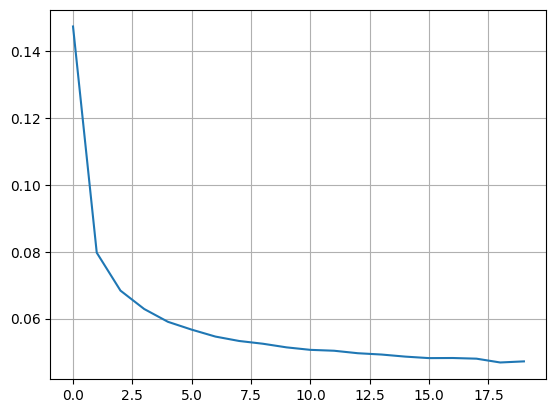

In [39]:
plt.figure()
plt.plot(d_losses)
plt.grid()
plt.show()

In [40]:
@torch.no_grad()
def sample_diffusion(model, n_samples=225):
    model.eval()

    x = torch.randn(n_samples, 1, 28, 28)

    for t in reversed(range(T)):
        t_batch = torch.full((n_samples,), t, dtype=torch.long)

        pred_noise = model(x, t_batch)

        beta_t = betas[t]
        alpha_t = alphas[t]
        alpha_b_t = alpha_bars[t]

        reverse_mean = 1/torch.sqrt(alpha_t) * (x - beta_t/(torch.sqrt(1-alpha_b_t)) * pred_noise)

        if t > 0:
            variance = posterior_var[t]
            noise = torch.randn_like(x)
            x = reverse_mean + torch.sqrt(variance)*noise
        else:
            x = reverse_mean

    return (x.clamp(-1, 1)+1)/2

In [41]:
samples = sample_diffusion(diffusion_model)

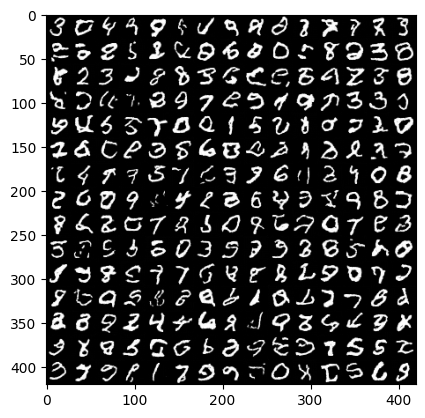

In [42]:
grid = make_grid(samples, nrow=15, padding=0)

plt.figure()
plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap='gray')
plt.show()